# Building Public Rankings, Part I — reproducible results companion

The CLI rebuilds every rating from raw data. This notebook is the review layer: it reads the frozen, auditable outputs, reproduces the main tables, and checks the central numerical claims.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

OUTPUT = Path.cwd()
if not (OUTPUT / "evaluation_manifest.json").exists():
    OUTPUT = Path.cwd() / "analysis" / "part1" / "output"
manifest = json.loads((OUTPUT / "evaluation_manifest.json").read_text())
manifest["dataset"]

{'cutoff_date': '2026-01-28',
 'duplicate_tournament_records': {'differing_duplicate_ids': 194,
  'duplicate_tournament_ids': 365,
  'extra_record_copies': 435,
  'identical_duplicate_ids': 171,
  'json_files': 181,
  'max_copies_for_one_id': 4,
  'records_loaded': 2686,
  'unique_tournament_ids': 2251},
 'eligibility': {'excluded_name_regex': '(?i)test|debug|demo|practice',
  'minimum_bracket_matches': 10,
  'minimum_participated_users': 16,
  'minimum_teams': 4,
  'settings_is_ranked': True,
  'valid_outcome': 'non-bye with a winner and loser'},
 'match_date_range': ['2024-05-13', '2026-01-28'],
 'matches': 28647,
 'source_root_at_execution': '/root/dev/sendouq_analysis',
 'timestamp_treatment': {'imputed_matches': 2385,
  'priority': ['last_game_finished_at',
   'match_created_at',
   'tournament_start_time'],
  'reason': 'the repository converter otherwise assigns a global/current timestamp to missing match times, which is invalid for temporal evaluation',
  'source_counts': {'last

## 1. What the dataset can see

In [2]:
display(pd.read_csv(OUTPUT / "tables/main_what_the_dataset_can_see.csv"))

,Measure,Result,What it means
0,Largest weak component,"5,518 / 5,518 players (100%)",The organized-play graph is connected enough f...
1,Top 100 in that component,100 / 100,Every displayed top player is connected to the...
2,Plus candidates in graph,459 / 468 (98.1%),Nine historical candidates never appear in a r...
3,Unique teammates,median 6; IQR 3–14,"The typical player changes teammates, but mixi..."
4,Unique opponents,median 48; IQR 20–151,Most players connect to many opponents.
5,Distinct lineups,median 3; IQR 1–8,Many players supply more than one lineup context.
6,Most-common-lineup share,median 53.8%; IQR 28.3–100%,A quarter of players never leave their most co...
7,Persistent lineup,841 players (15.2%),At least 80% of matches use one lineup (flag r...
8,Near-inseparable teammate,"1,746 players (31.6%)",One teammate appears in at least 90% of matche...


## 2. Strict walk-forward prediction

,method,matches,tournaments,match_micro_log_loss,tournament_macro_log_loss,brier_score,accuracy,paired_log_loss_difference_vs_loopr,paired_difference_ci_low,paired_difference_ci_high,tournaments_outperforming_loopr,median_per_tournament_difference
0,LOOPR,4397,110,0.512930,0.523166,0.170462,0.747555,0.000000,0.000000,0.000000,0,0.000000
1,Bradley–Terry (L2),4397,110,0.489261,0.502200,0.162732,0.749375,-0.023669,-0.037638,-0.010370,71,-0.010970
2,OpenSkill μ,4397,110,0.490019,0.503029,0.162706,0.753468,-0.022911,-0.034971,-0.010452,70,-0.019971
3,OpenSkill ordinal,4397,110,0.486015,0.507536,0.160656,0.755060,-0.026915,-0.046036,-0.008137,62,-0.008589
4,90-day win rate,4397,110,0.577789,0.586183,0.196675,0.687969,0.064859,0.047152,0.082177,23,0.052455
5,Chance (0.5),4397,110,0.693147,0.693147,0.250000,0.500000,0.180217,0.150471,0.205792,7,0.191134


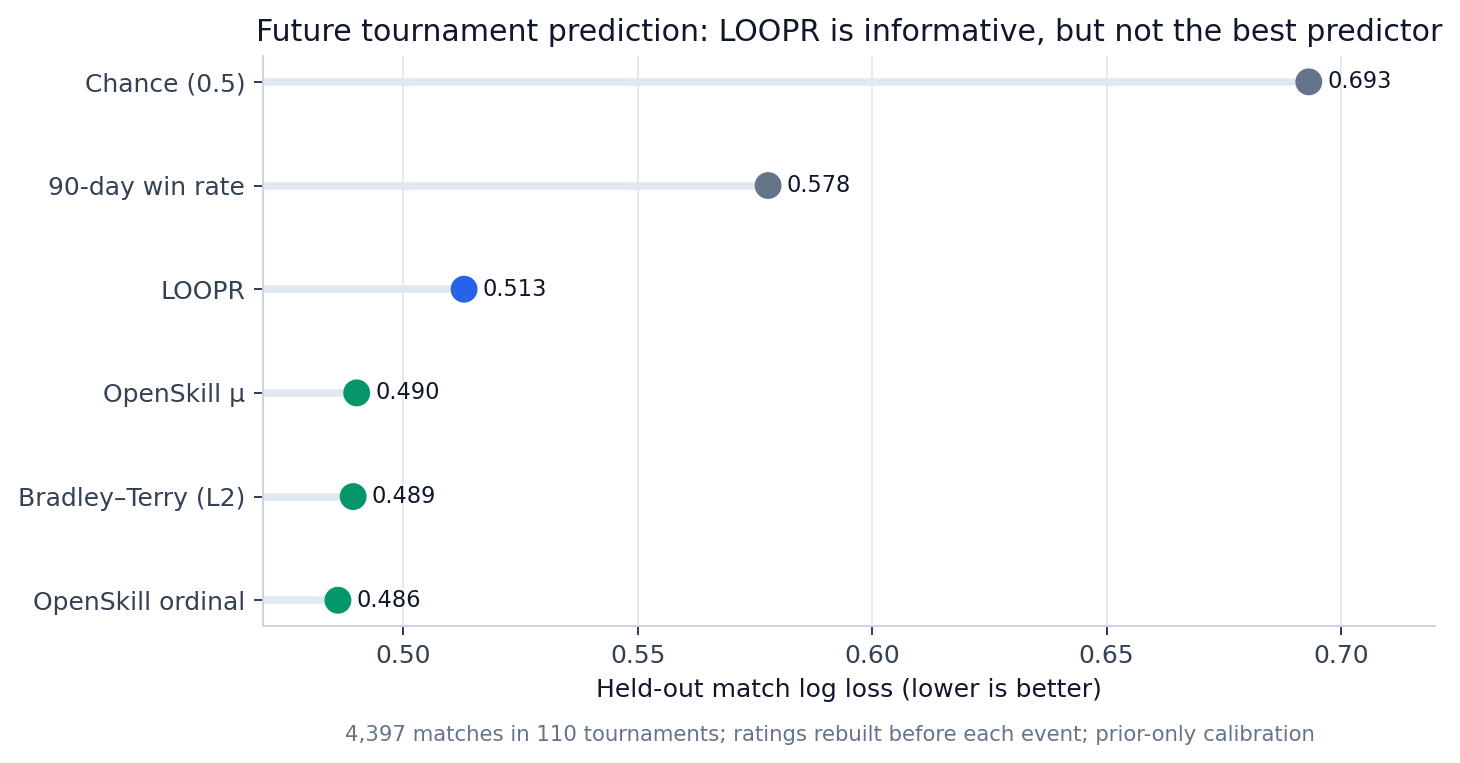

In [3]:
prediction = pd.read_csv(OUTPUT / "tables/prediction_summary.csv")
display(prediction)
loopr = prediction.set_index("method").loc["LOOPR"]
assert (
    loopr.match_micro_log_loss
    < prediction.set_index("method").loc["90-day win rate"].match_micro_log_loss
)
assert (
    loopr.match_micro_log_loss
    > prediction.set_index("method").loc["OpenSkill ordinal"].match_micro_log_loss
)
Image(filename=str(OUTPUT / "figures/01_future_prediction.png"))

## 3. Reliability

,calibration_bin,mean_predicted_probability,observed_win_rate,n_matches,min_probability,max_probability
0,0,0.217834,0.295455,880,0.006216,0.373372
1,1,0.486433,0.526735,879,0.373580,0.588173
2,2,0.670838,0.705347,879,0.588405,0.754267
3,3,0.831941,0.841866,879,0.754313,0.899683
4,4,0.949453,0.935227,880,0.899911,0.999634


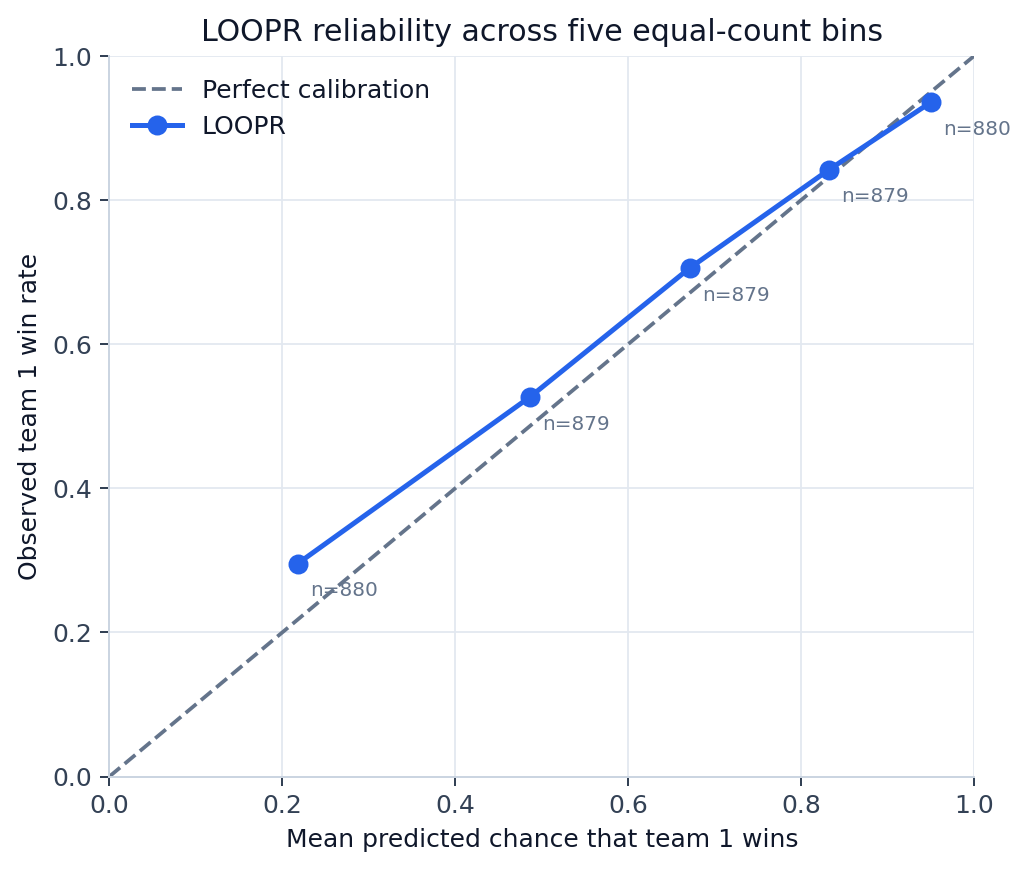

In [4]:
display(pd.read_csv(OUTPUT / "tables/loopr_calibration.csv"))
Image(filename=str(OUTPUT / "figures/02_loopr_calibration.png"))

## 4. Plus agreement and outcome shuffle

In [5]:
plus = pd.read_csv(OUTPUT / "tables/plus_methods.csv")
shuffle = json.loads((OUTPUT / "results/outcome_shuffle.json").read_text())
display(plus)
shuffle

,method,n,institutional_macro_auc,institutional_ci_low,institutional_ci_high,like_for_like_stratified_auc,stratified_ci_low,stratified_ci_high,eligible_passer_failer_pairs,loopr_minus_method_macro_auc,loopr_minus_method_macro_ci_low,loopr_minus_method_macro_ci_high,loopr_minus_method_stratified_auc,loopr_minus_method_stratified_ci_low,loopr_minus_method_stratified_ci_high
0,LOOPR,310,0.776756,0.719380,0.830557,0.615143,0.523129,0.706571,3500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,OpenSkill μ,310,0.614988,0.547778,0.678407,0.478857,0.390571,0.569729,3500,0.161768,0.103402,0.223662,0.136286,0.041429,0.234586
2,OpenSkill ordinal,310,0.590803,0.522707,0.660381,0.493429,0.401136,0.591721,3500,0.185953,0.122663,0.250479,0.121714,0.010564,0.230007
3,90-day win rate,310,0.504953,0.431878,0.575918,0.528000,0.443136,0.610000,3500,0.271803,0.196758,0.346623,0.087143,-0.020864,0.202579
4,Matches in prior 90d,310,0.459979,0.389986,0.532919,0.577429,0.489129,0.659861,3500,0.316777,0.210965,0.413818,0.037714,-0.095004,0.175154
5,Tournaments in prior 90d,310,0.444854,0.377038,0.517777,0.580857,0.491857,0.662293,3500,0.331902,0.228700,0.429927,0.034286,-0.099150,0.177718


{'null_macro_exceedance_p': 0.004975124378109453,
 'null_macro_mean': 0.5009434952459834,
 'null_macro_q025': 0.4032764106143223,
 'null_macro_q975': 0.5908747071645908,
 'null_procedure': 'independent fair-coin result reversal for every pre-vote match',
 'null_stratified_exceedance_p': 0.009950248756218905,
 'null_stratified_mean': 0.5058442857142857,
 'null_stratified_q025': 0.40159999999999996,
 'null_stratified_q975': 0.5952285714285716,
 'observed_macro_auc': 0.7767558449089546,
 'observed_stratified_auc': 0.6151428571428571,
 'repetitions': 200,
 'seed': 20260731}

## 5. Stability and leave-one-event robustness

In [6]:
display(pd.read_csv(OUTPUT / "tables/monthly_stability.csv"))
json.loads((OUTPUT / "results/leave_one_tournament_out.json").read_text())

,month_a,month_b,top100_retained,top100_retention,spearman_on_retained,median_absolute_rank_movement,p90_absolute_rank_movement
0,2024-12-31,2025-01-31,83,0.83,0.987889,5.0,12.8
1,2025-01-31,2025-02-28,80,0.80,0.957853,4.0,10.0
2,2025-02-28,2025-03-31,76,0.76,0.883363,10.0,23.0
3,2025-03-31,2025-04-30,85,0.85,0.950401,4.0,14.6
4,2025-04-30,2025-05-31,84,0.84,0.936519,4.0,16.0
5,2025-05-31,2025-06-30,96,0.96,0.972789,2.0,10.5
6,2025-06-30,2025-07-31,88,0.88,0.953982,3.0,12.0
7,2025-07-31,2025-08-31,88,0.88,0.986545,3.0,10.3
8,2025-08-31,2025-09-30,98,0.98,1.000000,2.0,2.0
9,2025-09-30,2025-10-31,82,0.82,0.991772,9.0,18.0


{'cutoff_date': '2026-01-28',
 'eligible_tournaments_removed': 665,
 'events_changing_rank_eligibility_for_at_least_one_original_top100_player': 18,
 'largest_observed_shared_player_rank_shift': 63.0,
 'largest_shared_shift_player_full_matches': 152,
 'largest_shared_shift_player_id': 21396,
 'largest_shared_shift_player_low_match_exposure': False,
 'largest_shared_shift_tournament_id': 3086,
 'largest_shared_shift_tournament_name': "Baja's Blast #31",
 'maximum_original_top100_players_made_rank_ineligible': 3,
 'median_of_median_abs_rank_changes': 0.0,
 'median_top100_retention': 1.0,
 'p90_of_all_tournament_p90_rank_changes': 1.0,
 'rank_eligibility_is_not_rank_movement': 'Players absent from the reduced active/ranked population are counted separately, not assigned a fictitious bottom rank; absence can reflect the 90-day activity rule rather than disappearance from the rating graph.',
 'top100_exposure_q25': 43.38943734140466,
 'top100_match_count_q25': 104.25,
 'worst_retention_tour

## 6. Parameter and property checks

In [7]:
half = pd.read_csv(OUTPUT / "tables/half_life_tradeoff.csv")
display(half)
primary = prediction.set_index("method").loc["LOOPR", "match_micro_log_loss"]
sweep = half.set_index("setting").loc["180d", "match_micro_log_loss"]
assert abs(primary - sweep) < 1e-12
json.loads((OUTPUT / "results/property_tests.json").read_text())

,setting,half_life_days,match_micro_log_loss,tournament_macro_log_loss,mean_monthly_top100_retention,median_monthly_rank_movement,plus_institutional_macro_auc_secondary,plus_like_for_like_auc_secondary
0,90d,90.0,0.510737,0.521977,0.841667,5.50,0.770364,0.621714
1,120d,120.0,0.511385,0.522154,0.836667,6.50,0.777816,0.622286
2,180d,180.0,0.512930,0.523166,0.830000,5.75,0.776756,0.615143
3,270d,270.0,0.514583,0.524424,0.831667,5.00,0.776610,0.615714
4,365d,365.0,0.515679,0.525300,0.830000,5.00,0.775647,0.614000
5,no_decay,NaN,0.519694,0.528606,0.825000,5.50,0.774929,0.611714


{'smoothing': [{'disappeared': 0,
   'exposure_band': 'high',
   'median_absolute_rank_change': 29.0,
   'median_absolute_score_change': 0.03569184050805571,
   'p90_absolute_rank_change': 192.5,
   'p90_absolute_score_change': 0.05366222296008705,
   'players': 6,
   'smoothing': False},
  {'disappeared': 0,
   'exposure_band': 'high',
   'median_absolute_rank_change': 30.5,
   'median_absolute_score_change': 0.0353763128647655,
   'p90_absolute_rank_change': 193.5,
   'p90_absolute_score_change': 0.05304694459624387,
   'players': 6,
   'smoothing': True},
  {'disappeared': 0,
   'exposure_band': 'low',
   'median_absolute_rank_change': 54.5,
   'median_absolute_score_change': 0.03211804280088346,
   'p90_absolute_rank_change': 138.0,
   'p90_absolute_score_change': 0.11711932045485593,
   'players': 6,
   'smoothing': False},
  {'disappeared': 0,
   'exposure_band': 'low',
   'median_absolute_rank_change': 53.5,
   'median_absolute_score_change': 0.031899874152782864,
   'p90_absolu

## Rebuild commands

See `README.md`. The expensive raw-data stages are intentionally CLI-driven and checkpointed; this notebook remains a compact audit surface.